# T's Approach

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import missingno as msno

In [2]:
df = pd.read_csv("data/BNPL_Financial_Default_Risk_Dataset.csv")

# DATA INSPECTION

In [3]:
print(df.shape)
print("-------------------------------")
df.info()

(10000, 11)
-------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Customer_ID                      10000 non-null  str    
 1   Age                              10000 non-null  int64  
 2   Employment_Status                10000 non-null  str    
 3   Income_USD                       9695 non-null   float64
 4   Credit_Score                     9702 non-null   float64
 5   Total_BNPL_Active_Loans          10000 non-null  int64  
 6   Total_BNPL_Debt_USD              10000 non-null  int64  
 7   Late_Payment_History             10000 non-null  str    
 8   Shopping_Category_Most_Frequent  10000 non-null  str    
 9   Average_Transaction_Value_USD    10000 non-null  int64  
 10  Default_Risk                     10000 non-null  str    
dtypes: float64(2), int64(4), str(5)
memory usage: 85

In [4]:
df.head()

,Customer_ID,Age,Employment_Status,Income_USD,Credit_Score,Total_BNPL_Active_Loans,Total_BNPL_Debt_USD,Late_Payment_History,Shopping_Category_Most_Frequent,Average_Transaction_Value_USD,Default_Risk
0,C00001,29,Employed,73405.0,637.0,2,193,No,Fashion,118,Low
1,C00002,64,Employed,53732.0,815.0,0,0,No,Electronics,662,Low
2,C00003,26,Freelancer,69930.0,723.0,2,273,No,Fashion,76,Low
3,C00004,19,Employed,96941.0,716.0,3,421,No,Home/Furniture,449,Low
4,C00005,55,Student,15959.0,675.0,2,145,No,Travel,974,Low


In [5]:
df.describe()

,Age,Income_USD,Credit_Score,Total_BNPL_Active_Loans,Total_BNPL_Debt_USD,Average_Transaction_Value_USD
count,10000.000000,9695.000000,9702.000000,10000.000000,10000.000000,10000.000000
mean,34.248300,53981.142651,663.671408,2.317000,348.805100,331.807700
std,12.911441,29797.373960,76.221869,1.854469,315.096249,264.360624
min,18.000000,5000.000000,300.000000,0.000000,0.000000,10.000000
25%,23.000000,21996.500000,620.000000,1.000000,142.000000,98.000000
50%,31.000000,58596.000000,673.000000,2.000000,262.500000,294.500000
75%,43.000000,77073.500000,717.000000,3.000000,467.000000,515.000000
max,64.000000,139452.000000,850.000000,10.000000,2731.000000,1420.000000


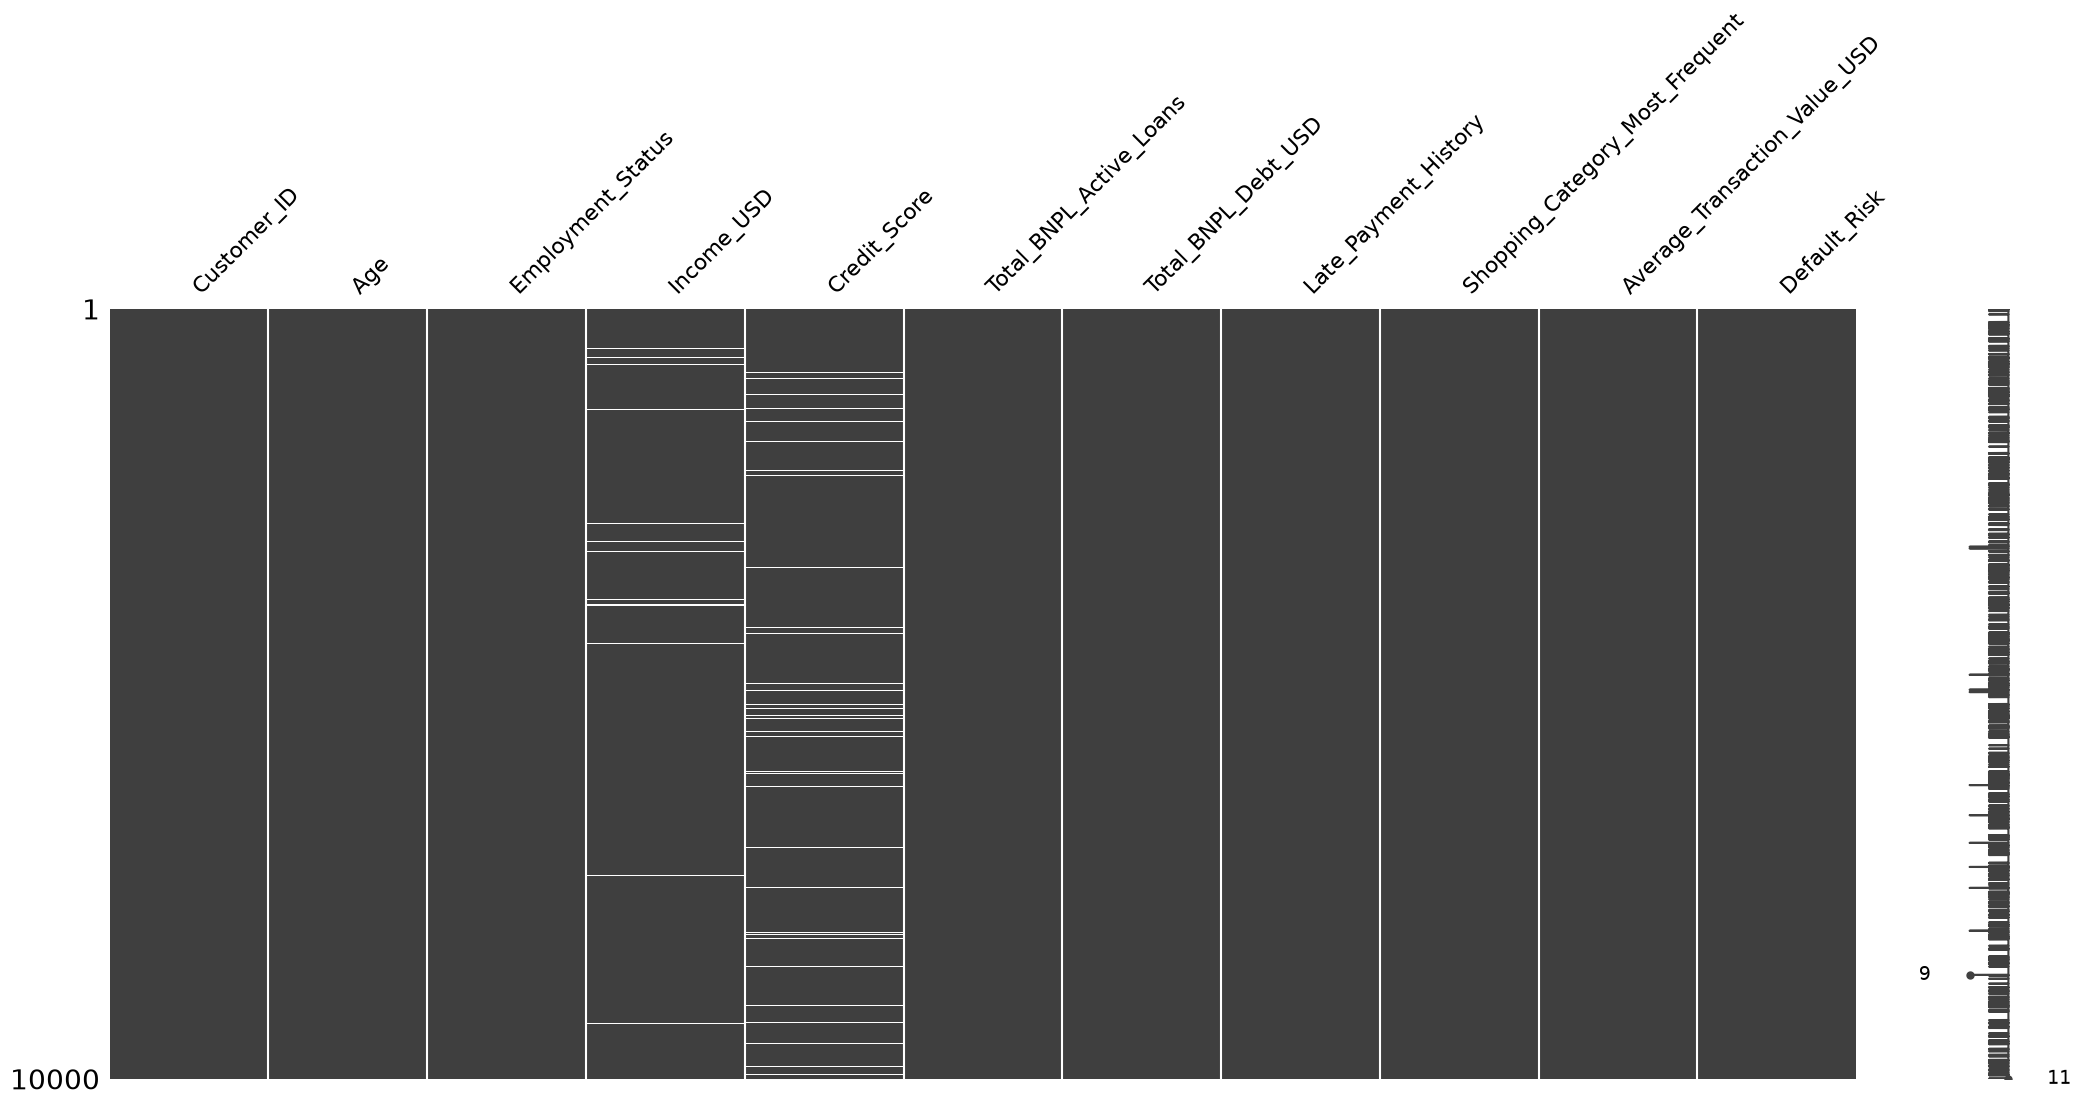

In [6]:
msno.matrix(df)
plt.show()

In [7]:
print("\n[Missing values per column]:")
print(df.isnull().sum())


[Missing values per column]:
Customer_ID                          0
Age                                  0
Employment_Status                    0
Income_USD                         305
Credit_Score                       298
Total_BNPL_Active_Loans              0
Total_BNPL_Debt_USD                  0
Late_Payment_History                 0
Shopping_Category_Most_Frequent      0
Average_Transaction_Value_USD        0
Default_Risk                         0
dtype: int64


Missing data in Income_USD and Credit_Score

In [8]:
df.duplicated().sum()

np.int64(0)

0 duplicate data

In [9]:
print(df["Default_Risk"].value_counts())

print("\n[Percentages]:")
print(df["Default_Risk"].value_counts(normalize=True) * 100)

Default_Risk
Low       8801
Medium     678
High       521
Name: count, dtype: int64

[Percentages]:
Default_Risk
Low       88.01
Medium     6.78
High       5.21
Name: proportion, dtype: float64


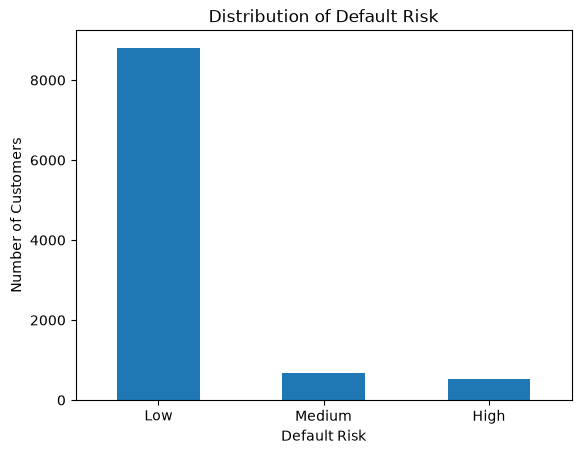

In [10]:
df["Default_Risk"].value_counts().plot(
    kind="bar"
)

plt.title("Distribution of Default Risk")
plt.xlabel("Default Risk")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.show()

Class Imbalance in Target Variable (Default Risk)
- Low (Majority): 88.01%
- Medium: 6.78%
- High: 5.21%

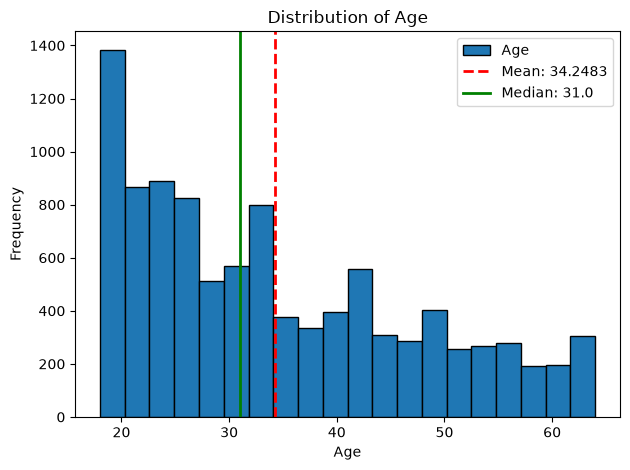

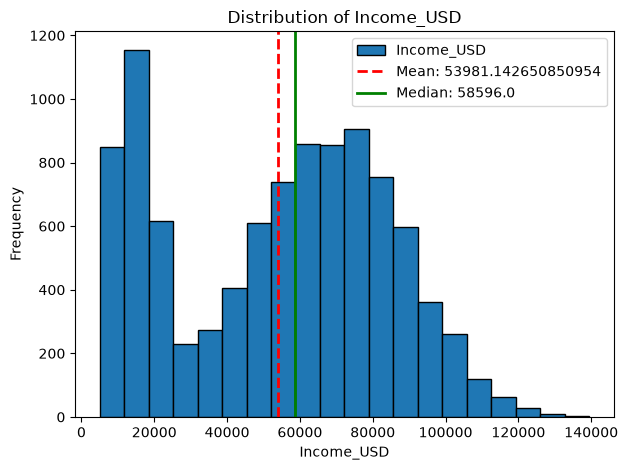

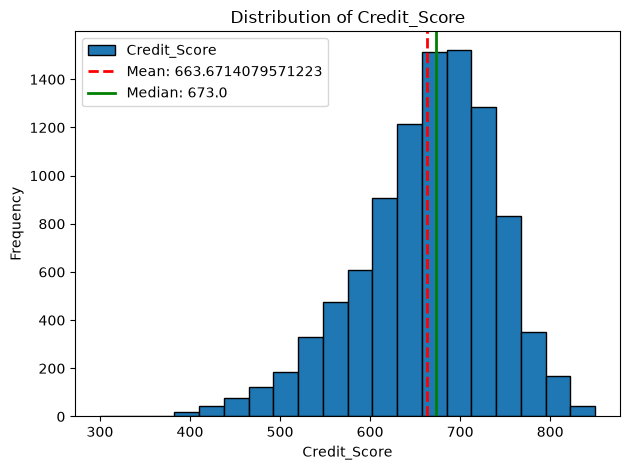

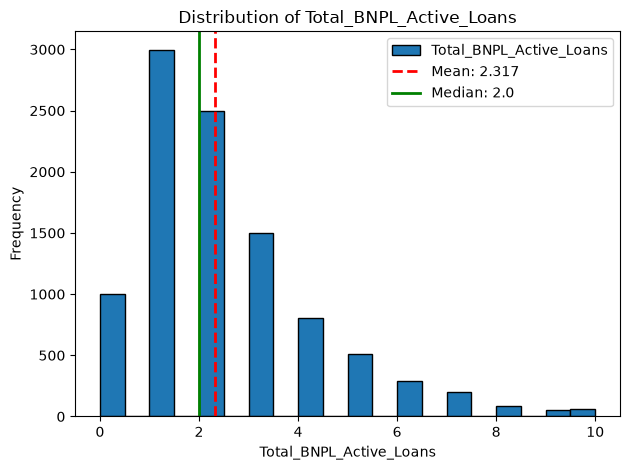

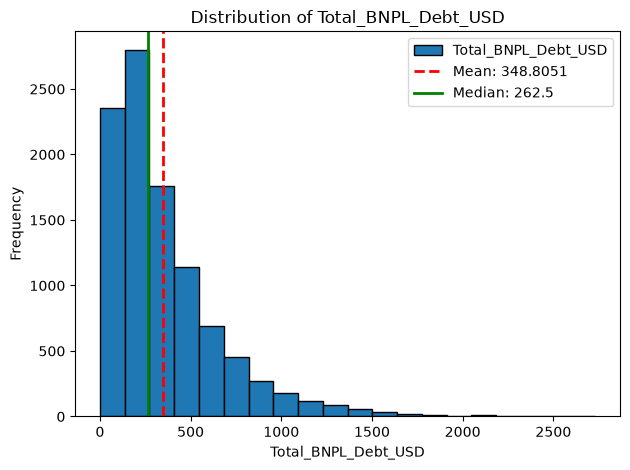

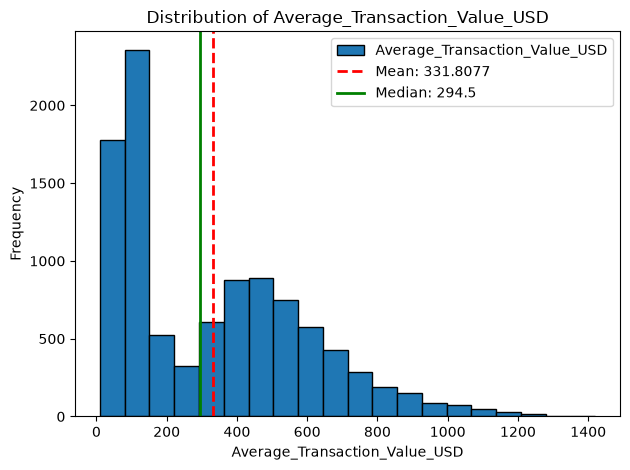

In [11]:
# Histogram distributions of each numerical feature

numeric_cols = df.select_dtypes(include='number').columns
n_cols = len(numeric_cols)

for col in numeric_cols:
    fig, ax = plt.subplots()

    df[col].plot(
        kind = 'hist',
        ax = ax,
        bins = 20,
        edgecolor = 'black'
    )
    
    mean_val = df[col].mean()
    median_val = df[col].median()

    ax.axvline(mean_val, color='red', linestyle='--', linewidth=2, label=f'Mean: {mean_val}')
    ax.axvline(median_val, color='green', linestyle='-', linewidth=2, label=f'Median: {median_val}')

    ax.set_title(f'Distribution of {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Frequency')
    ax.legend()

    plt.tight_layout()
    plt.show()

- Age lightly right skewed. 
- Income_USD would be normally distributed except the large frequencies in lower income_USD causes a left skew.
- Credit_score is lightly left skewed.
- Total_BNPL_Debt_USD is right skewed.
- Average_Transaction_Value_USD shares the same problem as Income_USD.

# ASSOCIATION ANALYSIS

In [12]:
# ============================ #
#     NUMERICAL ANALYSIS
# ============================ #

In [13]:
numeric_risk_features = [
    "Age",
    "Credit_Score",
    "Income_USD",
    "Total_BNPL_Active_Loans",
    "Total_BNPL_Debt_USD",
    "Average_Transaction_Value_USD"
]
print("[Group means of each numeric feature]\n==========================================")
print(
    df.groupby("Default_Risk")[numeric_risk_features].mean()
)
print("------------------------------------------------------------------------")
print("[Group medians of each numeric feature]\n==========================================")
print(
    df.groupby("Default_Risk")[numeric_risk_features].median()
)

[Group means of each numeric feature]
                    Age  Credit_Score    Income_USD  Total_BNPL_Active_Loans  \
Default_Risk                                                                   
High          34.124760    566.229862  11255.966403                 4.641075   
Low           34.267924    675.327439  58971.870238                 2.079536   
Medium        34.088496    587.321101  22131.662614                 3.613569   

              Total_BNPL_Debt_USD  Average_Transaction_Value_USD  
Default_Risk                                                      
High                   791.934741                     346.821497  
Low                    305.113055                     330.166004  
Medium                 575.446903                     341.581121  
------------------------------------------------------------------------
[Group medians of each numeric feature]
               Age  Credit_Score  Income_USD  Total_BNPL_Active_Loans  \
Default_Risk                            

In [14]:
# Box Plots

<Figure size 640x480 with 0 Axes>

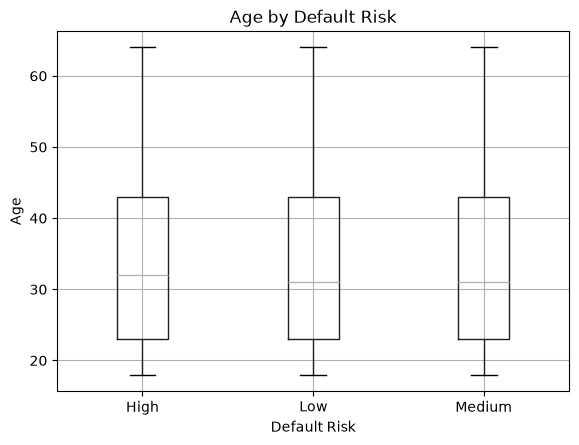

In [15]:
# Age
plt.figure()

df.boxplot(
    column="Age",
    by="Default_Risk"
)

plt.title("Age by Default Risk")
plt.suptitle("")
plt.xlabel("Default Risk")
plt.ylabel("Age")

plt.show()

Age has the same distributions by Default Risk class (Little variability differences)

<Figure size 640x480 with 0 Axes>

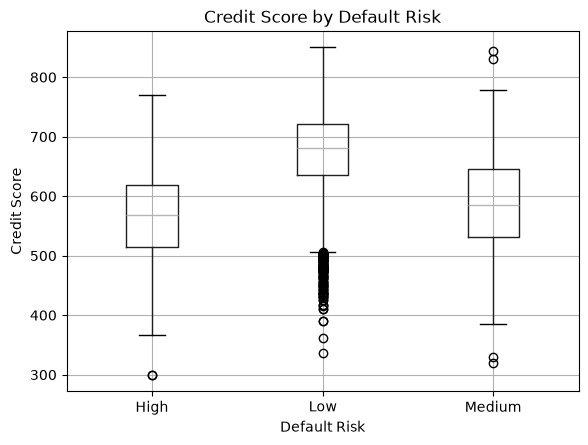

In [16]:
# Credit Score
plt.figure()

df.boxplot(
    column="Credit_Score",
    by="Default_Risk"
)

plt.title("Credit Score by Default Risk")
plt.suptitle("")
plt.xlabel("Default Risk")
plt.ylabel("Credit Score")

plt.show()

Lots of low outliers in Low for Credit Score

<Figure size 640x480 with 0 Axes>

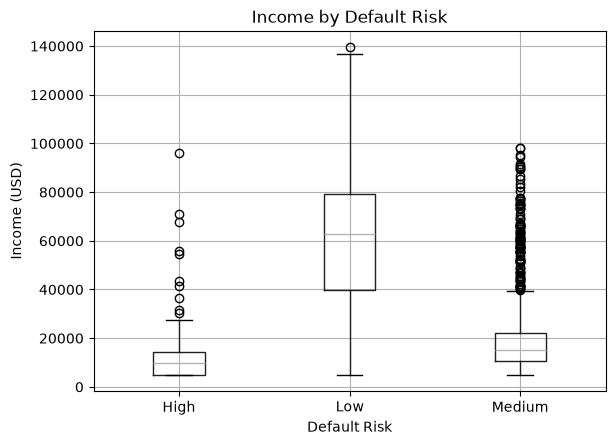

In [17]:
# Income_USD
plt.figure()

df.boxplot(
    column="Income_USD",
    by="Default_Risk"
)

plt.title("Income by Default Risk")
plt.suptitle("")
plt.xlabel("Default Risk")
plt.ylabel("Income (USD)")

plt.show()

- High and Medium Risks have high amounts of outliers when it comes to Income
- Low Risk has the widest IQR (greater variability)

<Figure size 640x480 with 0 Axes>

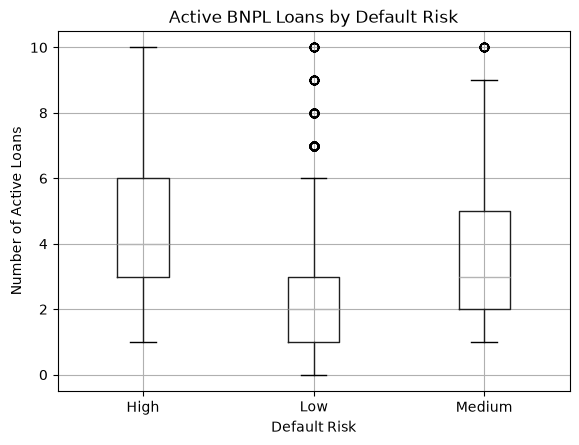

In [18]:
# Total_BNPL_Active_Loans
plt.figure()

df.boxplot(
    column="Total_BNPL_Active_Loans",
    by="Default_Risk"
)

plt.title("Active BNPL Loans by Default Risk")
plt.suptitle("")
plt.xlabel("Default Risk")
plt.ylabel("Number of Active Loans")

plt.show()

The larger the risk, the larger the number of active loans tends to be

<Figure size 640x480 with 0 Axes>

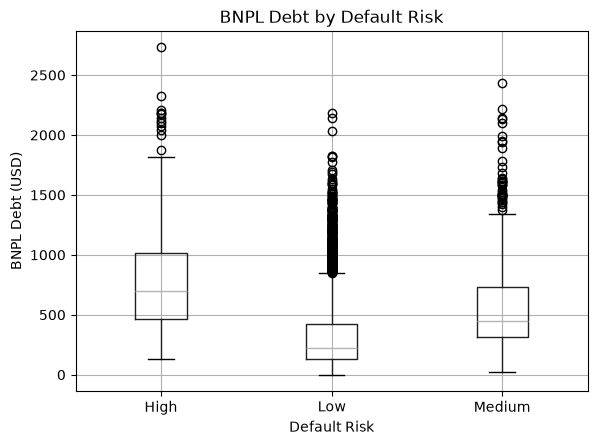

In [19]:
# Total_BNPL_Debt_USD
plt.figure()

df.boxplot(
    column="Total_BNPL_Debt_USD",
    by="Default_Risk"
)

plt.title("BNPL Debt by Default Risk")
plt.suptitle("")
plt.xlabel("Default Risk")
plt.ylabel("BNPL Debt (USD)")

plt.show()

- The larger the risk, the BNPL_Debt tends to be
- Noticably a lot of larger outliers

<Figure size 640x480 with 0 Axes>

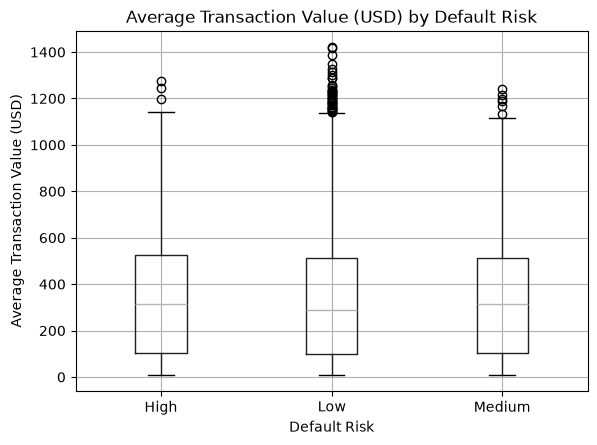

In [20]:
# Average_Transaction_Value_USD
plt.figure()

df.boxplot(
    column="Average_Transaction_Value_USD",
    by="Default_Risk"
)

plt.title("Average Transaction Value (USD) by Default Risk")
plt.suptitle("")
plt.xlabel("Default Risk")
plt.ylabel("Average Transaction Value (USD)")

plt.show()

- IQR of each risk level is the same for each Average_Transaction_Value (Same variability for this feature)
- Low Risk notably has a lot of outliers

In [21]:
from scipy.stats import f_oneway
numeric_risk_features = [
    "Credit_Score",
    "Income_USD",
    "Total_BNPL_Active_Loans",
    "Total_BNPL_Debt_USD"
]

Do these 4 different problematic features differ significantly among Low, Medium, and High-risk customers?

In [22]:
# One-way ANOVA test to test whether the 4 problematic numerical variables differ between the 3 risk groups:
print("H0: mu_low = mu_medium = mu_high")
print("Ha: At least one population mean differs")

for feature in numeric_risk_features:

    low = df[df["Default_Risk"] == "Low"][feature].dropna()
    medium = df[df["Default_Risk"] == "Medium"][feature].dropna()
    high = df[df["Default_Risk"] == "High"][feature].dropna()

    F, p = f_oneway(low, medium, high)

    print(f"\n\n[{feature} ANOVA]")
    print("F-statistic:", F)
    print("p-value:", p)
    # alpha = 0.05
    if p < 0.05:
        print("Reject H0: there is evidence that the group means differ.")
    else:
        print("Fail to reject H0: there is not sufficient evidence that the group means differ.")
    print("-----------------------------")

H0: mu_low = mu_medium = mu_high
Ha: At least one population mean differs


[Credit_Score ANOVA]
F-statistic: 1021.3985414355233
p-value: 0.0
Reject H0: there is evidence that the group means differ.
-----------------------------


[Income_USD ANOVA]
F-statistic: 1284.684305020827
p-value: 0.0
Reject H0: there is evidence that the group means differ.
-----------------------------


[Total_BNPL_Active_Loans ANOVA]
F-statistic: 743.0303856665506
p-value: 1.4139249195683436e-301
Reject H0: there is evidence that the group means differ.
-----------------------------


[Total_BNPL_Debt_USD ANOVA]
F-statistic: 917.2779250274357
p-value: 0.0
Reject H0: there is evidence that the group means differ.
-----------------------------


There is a difference in each 4 of the potentially problematic features. However, it’s not necessarily genuine or novel because it may be detecting the formula used to generate the target variable.

In [23]:
# Statistics of each problematic feature by target variable class
for feature in numeric_risk_features:

    print("\n" + "=" * 60)
    print(feature)
    print("=" * 60)

    print(
        df.groupby("Default_Risk")[feature]
        .agg(["count", "mean", "median", "std", "min", "max"])
        .round(2)
    )


Credit_Score
              count    mean  median    std    min    max
Default_Risk                                            
High            509  566.23   568.0  79.69  300.0  770.0
Low            8539  675.33   681.0  67.42  337.0  850.0
Medium          654  587.32   584.5  83.16  320.0  844.0

Income_USD
              count      mean   median       std     min       max
Default_Risk                                                      
High            506  11255.97   9789.0   8288.67  5000.0   95903.0
Low            8531  58971.87  62677.0  27649.88  5000.0  139452.0
Medium          658  22131.66  15206.5  19409.20  5000.0   98315.0

Total_BNPL_Active_Loans
              count  mean  median   std  min  max
Default_Risk                                     
High            521  4.64     4.0  2.26    1   10
Low            8801  2.08     2.0  1.65    0   10
Medium          678  3.61     3.0  2.20    1   10

Total_BNPL_Debt_USD
              count    mean  median     std  min   max
Def

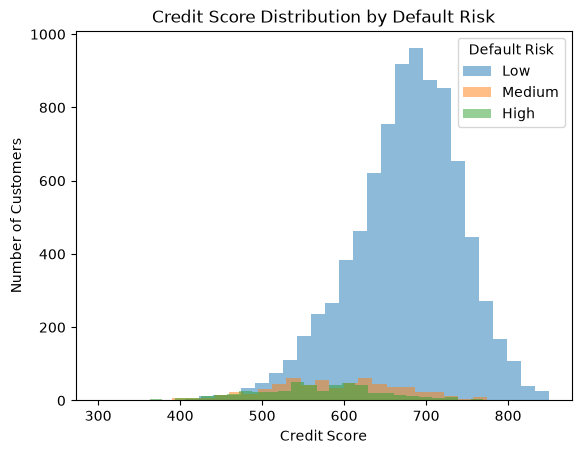

In [24]:
# Histogram by risk group for Credit_Score
plt.figure()

for risk in ["Low", "Medium", "High"]:

    values = df[df["Default_Risk"] == risk]["Credit_Score"].dropna()

    plt.hist(
        values,
        bins=30,
        alpha=0.5,
        label=risk
    )

plt.title("Credit Score Distribution by Default Risk")
plt.xlabel("Credit Score")
plt.ylabel("Number of Customers")
plt.legend(title="Default Risk")

plt.show()

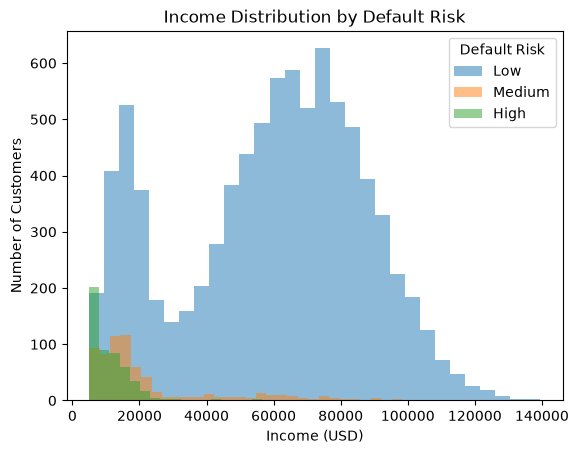

In [25]:
# Histogram by risk group for Income_USD
plt.figure()

for risk in ["Low", "Medium", "High"]:

    values = df[df["Default_Risk"] == risk]["Income_USD"].dropna()

    plt.hist(
        values,
        bins=30,
        alpha=0.5,
        label=risk
    )

plt.title("Income Distribution by Default Risk")
plt.xlabel("Income (USD)")
plt.ylabel("Number of Customers")
plt.legend(title="Default Risk")

plt.show()

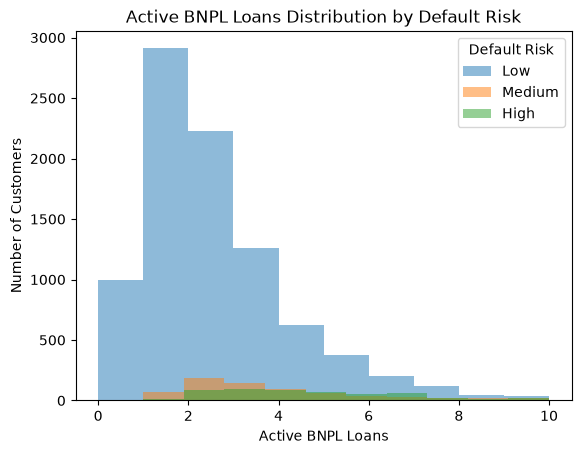

In [26]:
# Histogram by risk group for Total_BNPL_Active_Loans
plt.figure()

for risk in ["Low", "Medium", "High"]:

    values = df[df["Default_Risk"] == risk]["Total_BNPL_Active_Loans"].dropna()

    plt.hist(
        values,
        bins=10,
        alpha=0.5,
        label=risk
    )

plt.title("Active BNPL Loans Distribution by Default Risk")
plt.xlabel("Active BNPL Loans")
plt.ylabel("Number of Customers")
plt.legend(title="Default Risk")

plt.show()

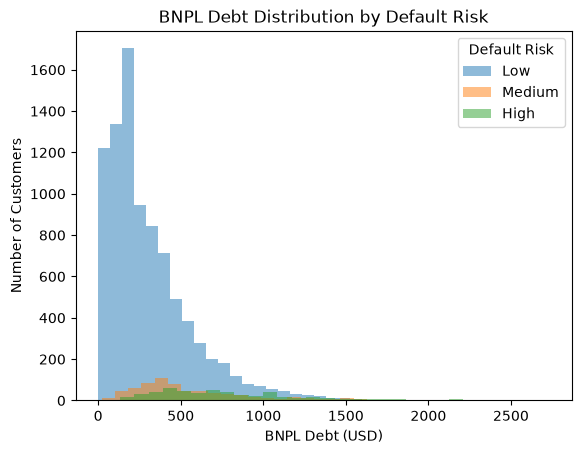

In [27]:
# Histogram by risk group for Total_BNPL_Debt_USD
plt.figure()

for risk in ["Low", "Medium", "High"]:

    values = df[df["Default_Risk"] == risk]["Total_BNPL_Debt_USD"].dropna()

    plt.hist(
        values,
        bins=30,
        alpha=0.5,
        label=risk
    )

plt.title("BNPL Debt Distribution by Default Risk")
plt.xlabel("BNPL Debt (USD)")
plt.ylabel("Number of Customers")
plt.legend(title="Default Risk")

plt.show()

Distributions of each risk groups don't appear to necessarily occupy different regions

count    9695.000000
mean        0.146146
std         0.257765
min         0.000000
25%         0.028578
50%         0.064717
75%         0.148581
max         5.080800
Name: BNPL_DTI, dtype: float64
--------------------------------------------------------------------------------
              count      mean    median       std       min       max
Default_Risk                                                         
High            506  0.963489  0.805866  0.561726  0.283380  5.080800
Low            8531  0.080325  0.053377  0.083512  0.000000  0.575084
Medium          658  0.370986  0.353146  0.160881  0.025963  0.935875
--------------------------------------------------------------------------------


<Figure size 640x480 with 0 Axes>

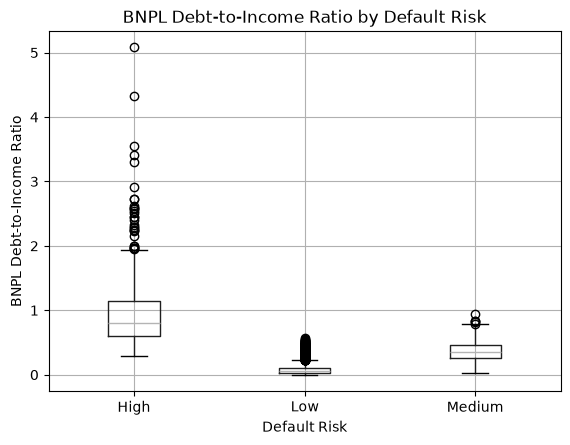

In [28]:
# Checking to see if synthetic data target variable is dependent on its stated construction variables
# Debt-to-Monthly-Income-Ratio
df["BNPL_DTI"] = (
    df["Total_BNPL_Debt_USD"] /
    (df["Income_USD"] / 12)
)

print(df["BNPL_DTI"].describe())
print("-" * 80)

print(
    df.groupby("Default_Risk")["BNPL_DTI"]
    .agg(["count", "mean", "median", "std", "min", "max"])
)

plt.figure()

# Boxplot
print("-" * 80)

df.boxplot(
    column="BNPL_DTI",
    by="Default_Risk"
)

plt.title("BNPL Debt-to-Income Ratio by Default Risk")
plt.suptitle("")
plt.xlabel("Default Risk")
plt.ylabel("BNPL Debt-to-Income Ratio")

plt.show()

The very strong separation of classes based on BNPL_DTI is evidence that the synthetic target may be strongly dependent on its stated construction variables.

In [29]:
# ============================ #
#     CATEGORICAL ANALYSIS
# ============================ #

In [30]:
from scipy.stats import chi2_contingency
categorical_features = [
    "Late_Payment_History",
    "Employment_Status",
    "Shopping_Category_Most_Frequent"
]

In [31]:
# Testing to see relationship between each categorical variable & default_risk
for feature in categorical_features:

    # Cross Table
    cross_table = pd.crosstab(
    df[feature],
    df["Default_Risk"]
    )

    # Cross Table Percentages
    table_percent = pd.crosstab(
        df[feature],
        df["Default_Risk"],
        normalize="index"
    ) * 100

    print(f"\n\n[{feature}]\n==============================================")
    print(cross_table, "\n----------------------------------------------")
    print(table_percent.round(2))



[Late_Payment_History]
Default_Risk          High   Low  Medium
Late_Payment_History                    
No                     181  7116     227
Yes                    340  1685     451 
----------------------------------------------
Default_Risk           High    Low  Medium
Late_Payment_History                      
No                     2.41  94.58    3.02
Yes                   13.73  68.05   18.21


[Employment_Status]
Default_Risk       High   Low  Medium
Employment_Status                    
Employed             13  5927      89
Freelancer           34  1377      84
Student             287  1307     374
Unemployed          187   190     131 
----------------------------------------------
Default_Risk        High    Low  Medium
Employment_Status                      
Employed            0.22  98.31    1.48
Freelancer          2.27  92.11    5.62
Student            14.58  66.41   19.00
Unemployed         36.81  37.40   25.79


[Shopping_Category_Most_Frequent]
Default_Risk     

[Late_Payment_History]:
- Customers with no late-payment history are overwhelmingly classified as Low Risk
- Customers with a late-payment history are much more likely to be classified as Medium/High risk

[Employment_Status]:
- For Employed, almost everyone is considered Low Risk
- For Freelance, same thing, but High Risk increases to 2.27%
- For Student, there's a difference in classes (66.41% Low; 19% Medium; 14.58% High)
- For Unemployed, there's a bigger difference (37.40% Low; 25.79% Medium; 36.81% High)

[Shopping_Category_Most_Frequent]:
- High Risk is consistently around 4-6%, but majority is labeled as Low Risk

In [32]:
# Chi^2 for categorical variables
print("H0: variable & default risk are independent")
print("Ha: variable & default risk are associated")
for feature in categorical_features:

    table = pd.crosstab(
        df[feature],
        df["Default_Risk"]
    )

    chi2, p, dof, expected = chi2_contingency(table)

    print(f"\n\n[{feature}]")
    print("-----------------------------")
    print("Chi-square:", chi2)
    print("p-value:", p)
    print("Degrees of freedom:", dof)
    if p < 0.05:
        print("Reject H0: the variables are associated.")
    else:
        print("Fail to reject H0: insufficient evidence of an association.")

H0: variable & default risk are independent
Ha: variable & default risk are associated


[Late_Payment_History]
-----------------------------
Chi-square: 1242.2682428194776
p-value: 1.7574320808810854e-270
Degrees of freedom: 2
Reject H0: the variables are associated.


[Employment_Status]
-----------------------------
Chi-square: 2904.150942746428
p-value: 0.0
Degrees of freedom: 6
Reject H0: the variables are associated.


[Shopping_Category_Most_Frequent]
-----------------------------
Chi-square: 3.401229581021738
p-value: 0.9067185796396604
Degrees of freedom: 8
Fail to reject H0: insufficient evidence of an association.


[Late_Payment_History]:
- p < 0.001 so there's a strong statistical evidence of an association between late-payment history and Default_Risk

[Employment_Status]:
- p < 0.001 so there's a strong statistical evidence of an association between Employment_status and Default_Risk

[Shopping_Category_Most_Frequent]:
- p > 0.05 so there's not enough evidence of an association between Shopping_Category_Most_Frequent and Default_Risk

In [33]:
# Correlation matrix
numeric_features = [
    "Age",
    "Income_USD",
    "Credit_Score",
    "Total_BNPL_Active_Loans",
    "Total_BNPL_Debt_USD",
    "Average_Transaction_Value_USD"
]

corr_matrix = df[numeric_features].corr()

print(corr_matrix.round(2))

                                Age  Income_USD  Credit_Score  \
Age                            1.00        0.00         -0.00   
Income_USD                     0.00        1.00          0.51   
Credit_Score                  -0.00        0.51          1.00   
Total_BNPL_Active_Loans       -0.01        0.01          0.01   
Total_BNPL_Debt_USD           -0.01        0.01          0.01   
Average_Transaction_Value_USD -0.01       -0.00         -0.01   

                               Total_BNPL_Active_Loans  Total_BNPL_Debt_USD  \
Age                                              -0.01                -0.01   
Income_USD                                        0.01                 0.01   
Credit_Score                                      0.01                 0.01   
Total_BNPL_Active_Loans                           1.00                 0.89   
Total_BNPL_Debt_USD                               0.89                 1.00   
Average_Transaction_Value_USD                     0.01                

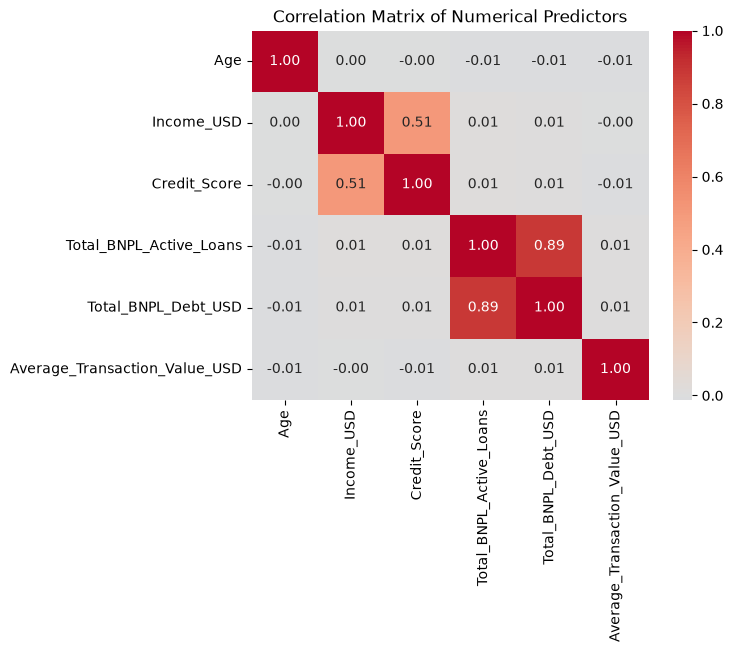

In [34]:
# Correlation heatmap
plt.figure()

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Numerical Predictors")
plt.show()

r(Active Loans, BNPL Debt) = 0.89, which is a very strong positive correlation. Customers with more active BNPL loans tend to have substantially higher total BNPL debt.

# SUMMARY
[Strong Associations]:
- Credit Score
- Income
- Active Loans
- BNPL Debt
- Late Payment History
- Employment Status

[Weak/No Evidence]:
- Shopping Category
- Age (This is surprising because studies show that younger consumers tend to use BNPL more and have associated risk correlations. We can chalk this up to problems due to the synthetic data)
- Average Transaction Value

[Notable Predictor Correlations]:
- Active Loans & BNPL Debt; r = 0.89
- Income & Credit Score; r = 0.51

# Modelling Set-Up:
[Target Variable]:
- Default_Risk; Low/Medium/High

[Predictors]:
- Age (Numerical)
- Employment_Status (Categorical)
- Income_USD (Numerical)
- Credit_Score (Numerical)
- Total_BNPL_Active_Loans (Numerical)
- Total_BNPL_Debt_USD (Numerical)
- Late_Payment_History (Binary; Categorical)
- Shopping_Category_Most_Frequent (Categorical)
- Average_Transaction_Value_USD (Numerical)
- BNPL_DTI (Engineered; Numerical)

[Filtered Predictors]:
- Age
- Employment_Status
- Shopping_Category_Most_Frequent
- Average_Transaction_Value_USD

In [35]:
# Target
y = df["Default_Risk"]

# Dataset with all predictors
X_all = df.drop(columns=["Customer_ID", "Default_Risk"])

# Restricted dataset without the potentially problematic predictors
X_filtered = X_all.drop(columns=[
    "Income_USD",
    "Credit_Score",
    "Total_BNPL_Active_Loans",
    "Total_BNPL_Debt_USD",
    "Late_Payment_History",
    "BNPL_DTI"
])

print("All predictors:")
print(X_all.columns.tolist())

print("\nFiltered predictors:")
print(X_filtered.columns.tolist())

All predictors:
['Age', 'Employment_Status', 'Income_USD', 'Credit_Score', 'Total_BNPL_Active_Loans', 'Total_BNPL_Debt_USD', 'Late_Payment_History', 'Shopping_Category_Most_Frequent', 'Average_Transaction_Value_USD', 'BNPL_DTI']

Filtered predictors:
['Age', 'Employment_Status', 'Shopping_Category_Most_Frequent', 'Average_Transaction_Value_USD']


In [36]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

In [37]:
# 80/20 train/test split:
X_train, X_test, y_train, y_test = train_test_split(
    X_all,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Verifying split:
print("Training set:")
print(y_train.value_counts())
print(y_train.value_counts(normalize=True) * 100)

print("\nTest set:")
print(y_test.value_counts())
print(y_test.value_counts(normalize=True) * 100)

Training set:
Default_Risk
Low       7041
Medium     542
High       417
Name: count, dtype: int64
Default_Risk
Low       88.0125
Medium     6.7750
High       5.2125
Name: proportion, dtype: float64

Test set:
Default_Risk
Low       1760
Medium     136
High       104
Name: count, dtype: int64
Default_Risk
Low       88.0
Medium     6.8
High       5.2
Name: proportion, dtype: float64


In [38]:
numeric_features = [
    "Age",
    "Income_USD",
    "Credit_Score",
    "Total_BNPL_Active_Loans",
    "Total_BNPL_Debt_USD",
    "Average_Transaction_Value_USD",
    "BNPL_DTI"
]

categorical_features = [
    "Employment_Status",
    "Late_Payment_History",
    "Shopping_Category_Most_Frequent"
]

# Setting pipeline for numeric variables:
numeric_pipeline = Pipeline([
    # Median imputation 
    ("imputer", SimpleImputer(strategy="median")),
    # LogScaling
    ("scaler", StandardScaler())
])

# Setting pipeline for categorical variables:
categorical_pipeline = Pipeline([
    (
        "encoder",
        # OneHotEncoding
        OneHotEncoder(
            handle_unknown="ignore",
            drop=None
        )
    )
])

# Combining the two pipelines:
preprocessor = ColumnTransformer([
    (
        "numeric",
        numeric_pipeline,
        numeric_features
    ),
    (
        "categorical",
        categorical_pipeline,
        categorical_features
    )
])

In [39]:
# Preprocessing Test:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training processed shape:", X_train_processed.shape)
print("Test processed shape:", X_test_processed.shape)

Training processed shape: (8000, 18)
Test processed shape: (2000, 18)


# Baseline

In [40]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [41]:
# Predicts Low Risk for every customer
dummy_model = DummyClassifier(
    strategy="most_frequent"
)

dummy_model.fit(X_train, y_train)

dummy_predictions = dummy_model.predict(X_test)

In [42]:
# Baseline Evaluation:

print("Majority-Class Baseline")
print("-" * 80)

print("Accuracy:", accuracy_score(y_test, dummy_predictions))
print("Balanced Accuracy:", balanced_accuracy_score(y_test, dummy_predictions))
print("Macro F1:", f1_score(y_test, dummy_predictions, average="macro"))

Majority-Class Baseline
--------------------------------------------------------------------------------
Accuracy: 0.88
Balanced Accuracy: 0.3333333333333333
Macro F1: 0.3120567375886525


How well can we do without using any predictors whatsoever? Pretty badly.

# Quick Modelling for Comparison

In [43]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder

- Logistic Regression gives us an interpretable linear baseline and is a simple model to use to examine coefficients and relationships to compare against more complex ML algorithms.
- Random Forest allows us to figure out nonlinear relationships and interactions between predictors to find complex patterns that Logistic Regression may miss
- XGBoost is captures even more sophisticated nonlinear patterns and interactions beyond what Random Forest can do.

In [44]:
# Multinomial Logistic Regression
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000
        )
    )
])

logistic_model.fit(X_train, y_train)
logistic_predictions = logistic_model.predict(X_test)

# Logistic Regression Evaluation:
print("Logistic Regression")
print("-" * 80)

print("Accuracy:", accuracy_score(y_test, logistic_predictions))
print("Balanced Accuracy:", balanced_accuracy_score(y_test, logistic_predictions))
print("Macro F1:", f1_score(y_test, logistic_predictions, average="macro"))

print("\nClassification Report:")
print(classification_report(y_test, logistic_predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, logistic_predictions))

Logistic Regression
--------------------------------------------------------------------------------
Accuracy: 0.968
Balanced Accuracy: 0.8936437337172632
Macro F1: 0.8981643722339974

Classification Report:
              precision    recall  f1-score   support

        High       0.94      0.92      0.93       104
         Low       0.98      0.99      0.98      1760
      Medium       0.78      0.77      0.78       136

    accuracy                           0.97      2000
   macro avg       0.90      0.89      0.90      2000
weighted avg       0.97      0.97      0.97      2000


Confusion Matrix:
[[  96    4    4]
 [   0 1735   25]
 [   6   25  105]]


- Strong classification performance across all 3 risk categories, specifically for high-risk
- Model seems to have a hard time distinguishing Medium from Low than High from Low

In [45]:
# Random Forest
random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    (
        "classifier",
        RandomForestClassifier(
            random_state=42
        )
    )
])

random_forest_model.fit(X_train, y_train)
rf_predictions = random_forest_model.predict(X_test)

# Random Forest Evaluation:
print("Random Forest")
print("-" * 80)

print("Accuracy:", accuracy_score(y_test, rf_predictions))
print("Balanced Accuracy:", balanced_accuracy_score(y_test, rf_predictions))
print("Macro F1:", f1_score(y_test, rf_predictions, average="macro"))

print("\nClassification Report:")
print(classification_report(y_test, rf_predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_predictions))

Random Forest
--------------------------------------------------------------------------------
Accuracy: 0.965
Balanced Accuracy: 0.8661216234745647
Macro F1: 0.8753705785356258

Classification Report:
              precision    recall  f1-score   support

        High       0.90      0.90      0.90       104
         Low       0.98      0.99      0.99      1760
      Medium       0.78      0.71      0.74       136

    accuracy                           0.96      2000
   macro avg       0.89      0.87      0.88      2000
weighted avg       0.96      0.96      0.96      2000


Confusion Matrix:
[[  94    3    7]
 [   0 1740   20]
 [  11   29   96]]


- Great at predicting Low Risk
- Struggles with Medium Risk
- This makes sense since Medium Risk can overlap with Low & High Risk

In [46]:
# Encode target for XGBoost
label_encoder = LabelEncoder()

y_train_xgb = label_encoder.fit_transform(y_train)
y_test_xgb = label_encoder.transform(y_test)

# XGBoost
xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    (
        "classifier",
        XGBClassifier(
            random_state=42
        )
    )
])

xgb_model.fit(X_train, y_train_xgb)

# Predict numeric classes
xgb_predictions_encoded = xgb_model.predict(X_test)

# Convert predictions back to original labels
xgb_predictions = label_encoder.inverse_transform(
    xgb_predictions_encoded
)

# XGBoost Evaluation
print("\nXGBoost")
print("-" * 80)

print("Accuracy:", accuracy_score(y_test, xgb_predictions))
print("Balanced Accuracy:", balanced_accuracy_score(y_test, xgb_predictions))
print("Macro F1:", f1_score(y_test, xgb_predictions, average="macro"))

print("\nClassification Report:")
print(classification_report(y_test, xgb_predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, xgb_predictions))


XGBoost
--------------------------------------------------------------------------------
Accuracy: 0.967
Balanced Accuracy: 0.8872334773070066
Macro F1: 0.8882800571443297

Classification Report:
              precision    recall  f1-score   support

        High       0.92      0.90      0.91       104
         Low       0.99      0.99      0.99      1760
      Medium       0.76      0.77      0.77       136

    accuracy                           0.97      2000
   macro avg       0.89      0.89      0.89      2000
weighted avg       0.97      0.97      0.97      2000


Confusion Matrix:
[[  94    2    8]
 [   0 1735   25]
 [   8   23  105]]


Strongest overall performance.

# More Complex Modelling

# Feature Sets
[Demographics]:
- Age
- Employment_Status

[... + Financial]:
- ...
- Income_USD
- Credit_Score

[... + BNPL]:
- ...
- Total_BNPL_Active_Loans
- Total_BNPL_Debt_USD
- Shopping_Category_Most_Frequent
- Average_Transaction_Value_USD

[... + Payment]:
- ...
- Late_Payment_History

[Full + BNPL DTI]:
- ...
- BNPL_DTI

[Restricted]:
- Age
- Employment_Status
- Shopping_Category_Most_Frequent
- Average_Transaction_Value_USD


In [47]:
feature_sets = {

    "Demographics": [
        "Age",
        "Employment_Status"
    ],

    "Demographics + Financial": [
        "Age",
        "Employment_Status",
        "Income_USD",
        "Credit_Score"
    ],

    "Demographics + Financial + BNPL": [
        "Age",
        "Employment_Status",
        "Income_USD",
        "Credit_Score",
        "Total_BNPL_Active_Loans",
        "Total_BNPL_Debt_USD",
        "Shopping_Category_Most_Frequent",
        "Average_Transaction_Value_USD"
    ],

    "Full": [
        "Age",
        "Employment_Status",
        "Income_USD",
        "Credit_Score",
        "Total_BNPL_Active_Loans",
        "Total_BNPL_Debt_USD",
        "Shopping_Category_Most_Frequent",
        "Average_Transaction_Value_USD",
        "Late_Payment_History"
    ],

    "Full + BNPL_DTI": [
        "Age",
        "Employment_Status",
        "Income_USD",
        "Credit_Score",
        "Total_BNPL_Active_Loans",
        "Total_BNPL_Debt_USD",
        "Shopping_Category_Most_Frequent",
        "Average_Transaction_Value_USD",
        "Late_Payment_History",
        "BNPL_DTI"
    ],

    "Restricted": [
        "Age",
        "Employment_Status",
        "Shopping_Category_Most_Frequent",
        "Average_Transaction_Value_USD"
    ]
}

# Preprocessing Function

In [48]:
def make_preprocessor(features, scale_numeric=True):

    # Defines each numeric feature
    numeric_features = [
        feature for feature in features
        if feature in [
            "Age",
            "Income_USD",
            "Credit_Score",
            "Total_BNPL_Active_Loans",
            "Total_BNPL_Debt_USD",
            "Average_Transaction_Value_USD",
            "BNPL_DTI"
        ]
    ]

    # Defines each categorical feature
    categorical_features = [
        feature for feature in features
        if feature in [
            "Employment_Status",
            "Late_Payment_History",
            "Shopping_Category_Most_Frequent"
        ]
    ]

    # Pipeline if numeric
    if scale_numeric:
        # This is for Logistic Regression
        numeric_pipeline = Pipeline([
            # Mean imputation
            ("imputer", SimpleImputer(strategy="median")),
            # Scaling
            ("scaler", StandardScaler())
        ])
    else:
        # This is for Random Forest & XGBoost
        numeric_pipeline = Pipeline([
            # Mean imputation only
            ("imputer", SimpleImputer(strategy="median"))
        ])

    # Pipeline if categorical
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    # Making the preprocessor by combining the two pipelines
    preprocessor = ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ])

    return preprocessor

In [49]:
# To optimize later:
models = {

    "Logistic Regression": LogisticRegression(
        max_iter=1000
    ),

    "Random Forest": RandomForestClassifier(
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        random_state=42
    )
}

In [50]:
results = []

# Encode target for XGBoost only
label_encoder = LabelEncoder()
y_train_xgb = label_encoder.fit_transform(y_train)

for feature_set_name, features in feature_sets.items():

    X_train_subset = X_train[features]
    X_test_subset = X_test[features]

    for model_name, model in models.items():

        # Create preprocessing
        preprocessor = make_preprocessor(
            features,
            scale_numeric=(model_name == "Logistic Regression")
        )

        # Create pipeline
        pipeline = Pipeline([
            ("preprocessor", preprocessor),
            ("classifier", model)
        ])

        # --------------------------------------------------
        # Fit and predict
        # --------------------------------------------------

        if model_name == "XGBoost":
            # XGBoost needs numeric class labels
            pipeline.fit(
                X_train_subset,
                y_train_xgb
            )

            predictions_encoded = pipeline.predict(
                X_test_subset
            )

            # Transforms XGBoost's predictions back before calculating metrics against original y_test
            predictions = label_encoder.inverse_transform(
                predictions_encoded.astype(int)
            )

        else:

            # Logistic Regression and Random Forest
            pipeline.fit(
                X_train_subset,
                y_train
            )

            predictions = pipeline.predict(
                X_test_subset
            )

        # --------------------------------------------------
        # Evaluation
        # --------------------------------------------------

        accuracy = accuracy_score(
            y_test,
            predictions
        )

        balanced_accuracy = balanced_accuracy_score(
            y_test,
            predictions
        )

        macro_precision = precision_score(
            y_test,
            predictions,
            average="macro"
        )

        macro_recall = recall_score(
            y_test,
            predictions,
            average="macro"
        )

        macro_f1 = f1_score(
            y_test,
            predictions,
            average="macro"
        )

        # --------------------------------------------------
        # Save results
        # --------------------------------------------------

        results.append({
            "Feature Set": feature_set_name,
            "Model": model_name,
            "Accuracy": accuracy,
            "Balanced Accuracy": balanced_accuracy,
            "Macro Precision": macro_precision,
            "Macro Recall": macro_recall,
            "Macro F1": macro_f1
        })

c:\Users\peetz\Documents\IRL Stuffs\Schools\UTA-Fall2026\VSCode Stuffs\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\peetz\Documents\IRL Stuffs\Schools\UTA-Fall2026\VSCode Stuffs\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [51]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by=["Macro F1", "Balanced Accuracy"],
    ascending=False
)

comparison_table = results_df[
    [
        "Feature Set",
        "Model",
        "Balanced Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1"
    ]
].copy()

comparison_table = comparison_table.sort_values(
    ["Feature Set", "Model"]
)

comparison_table.round(4)

,Feature Set,Model,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1
0,Demographics,Logistic Regression,0.4108,0.4164,0.4108,0.4101
1,Demographics,Random Forest,0.3980,0.4860,0.3980,0.4119
2,Demographics,XGBoost,0.4108,0.5053,0.4108,0.4261
3,Demographics + Financial,Logistic Regression,0.4557,0.6081,0.4557,0.4671
4,Demographics + Financial,Random Forest,0.4766,0.5288,0.4766,0.4906
5,Demographics + Financial,XGBoost,0.4813,0.5446,0.4813,0.4991
6,Demographics + Financial + BNPL,Logistic Regression,0.7392,0.7756,0.7392,0.7534
7,Demographics + Financial + BNPL,Random Forest,0.7360,0.7659,0.7360,0.7470
8,Demographics + Financial + BNPL,XGBoost,0.7496,0.7642,0.7496,0.7567
9,Full,Logistic Regression,0.7898,0.8122,0.7898,0.8006


In [52]:
best_models = (
    results_df
    .sort_values("Macro F1", ascending=False)
    .groupby("Feature Set")
    .first()
    .reset_index()
)

best_models[
    [
        "Feature Set",
        "Model",
        "Accuracy",
        "Balanced Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1"
    ]
]

,Feature Set,Model,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1
0,Demographics,XGBoost,0.8775,0.410795,0.505281,0.410795,0.426149
1,Demographics + Financial,XGBoost,0.8765,0.481283,0.544641,0.481283,0.499074
2,Demographics + Financial + BNPL,XGBoost,0.9320,0.749585,0.764184,0.749585,0.756660
3,Full,XGBoost,0.9610,0.852544,0.865090,0.852544,0.858370
4,Full + BNPL_DTI,Logistic Regression,0.9680,0.893644,0.902773,0.893644,0.898164
5,Restricted,Random Forest,0.8550,0.431672,0.470489,0.431672,0.446159


Demographics alone has poor performance. As we added in features that might've been used for the synthetic target variable, the performance of each model becomes better. This is very apparent when it comes to directly adding BNPL characteristics, with Payment improving it even more. When we used our engineered feature, which uses the features that are assumed to be used for the synthetic target variable, the performance of each model improves the best with Logistic Regression performing the best of the 3. This is expected since the engineered feature gives extra weight to the other features used to make it. As for the restricted features, Random Forest performs the best. Otherwise, XGBoost dominates each feature set. XGBoost dominates due to it being a good model for nonlinear relationships and interactions between variables. With BNPL_DTI provided, Logistic Regression has an explicit engineered representation of the relationship between BNPL debt and income, reducing the need for the model to learn that nonlinear relationship directly. Random Forest is able to extract the remaining nonlinear categorical structure when the biggest predictors were removed, which is why it performs best on the restricted feature set.

[Feature Set Progression]:
Demographics -> + Financial -> + BNPL -> + Payment History -> + BNPL_DTI

[Balanced Accuracy Progression]:
0.411 -> 0.481 -> 0.750 -> 0.853 -> 0.894

BNPL financial burden and repayment behavior are much more informative for synthetic risk classification than basic demographics or shopping preferences

# Hyperparameter Tuning (By Macro F1-Score)
[Logistic Regression]:
- C controls regularization strength
- class_weight gives greater weight to observations from underrepresented classes

[Random Forest]:
- n_estimator controls number of trees to stabilize predictions
- max_depth controls depth of trees to learn detailed patterns. Can lead to overfitting or be more constrained.
- min_samples_leaf controls minimum observations allowed in a terminal leaf to prevent trees from creating extremely specific rules to control overfitting
- class_weight

[XGBoost]:
- n_estimators
- max_depth
- learning_rate controls how strongly each new tree modifies the current model to control how many trees are needed
- subsample controls what fraction of training observations each boosting round uses to possibly reduce overfitting
- colsample_bytree controls what fraction of predictors each tree gets to consider to introduce useful randomness and reduce overfitting

[5-fold CV]:
- Divides observations into 5 groups to get evaluated 5 times for average performance
- Doing this since our target is imbalanced

[Held-out Test Set]:
- 80% training has the feature decisions, hyperparameters, and 5-fold CV
- 20% test hasn't been touched yet
- We use this to test the model on genuinely new, unseen info

In [53]:
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import cross_validate
from sklearn.model_selection import cross_val_score

In [54]:
# Testing different parameters for tuning:
# NOTE: This is like, 290 fits
param_grids = {

    "Logistic Regression": {
        "classifier__C": [0.1, 1, 10],
        "classifier__class_weight": [None, "balanced"]
    },

    "Random Forest": {
        "classifier__n_estimators": [100, 200],
        "classifier__max_depth": [None, 10, 20],
        "classifier__min_samples_leaf": [1, 2, 5],
        "classifier__class_weight": [None, "balanced"]
    },

    "XGBoost": {
        "classifier__n_estimators": [100, 200],
        "classifier__max_depth": [3, 5],
        "classifier__learning_rate": [0.05, 0.1],
        "classifier__subsample": [0.8, 1.0]
    }
}

# 5-fold CV
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [55]:
# Testing out the parameters for Logistic Regression
logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000))
])

logistic_grid = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=param_grids["Logistic Regression"],
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1
)

logistic_grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._iter=2000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__C': [0.1, 1, ...], 'classifier__class_weight': [None, 'balanced']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbos

In [56]:
print("Best Parameters:")
print(logistic_grid.best_params_)

print("\nBest Logistic Regression CV Macro F1:")
print(logistic_grid.best_score_)

best_logistic = logistic_grid.best_estimator_
logistic_tuned_cv = logistic_grid.best_score_

Best Parameters:
{'classifier__C': 0.1, 'classifier__class_weight': 'balanced'}

Best Logistic Regression CV Macro F1:
0.46020287937841753


In [57]:
best_logistic = logistic_grid.best_estimator_
tuned_predictions = best_logistic.predict(X_test)

print("Tuned Logistic Regression")
print("-" * 80)

print("Accuracy:",
      accuracy_score(y_test, tuned_predictions))

print("Balanced Accuracy:",
      balanced_accuracy_score(y_test, tuned_predictions))

print("Macro F1:",
      f1_score(y_test, tuned_predictions, average="macro"))

print("\nClassification Report:")
print(classification_report(y_test, tuned_predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, tuned_predictions))

Tuned Logistic Regression
--------------------------------------------------------------------------------
Accuracy: 0.7575
Balanced Accuracy: 0.5726664267105444
Macro F1: 0.45728877880870017

Classification Report:
              precision    recall  f1-score   support

        High       0.19      0.70      0.30       104
         Low       0.97      0.80      0.88      1760
      Medium       0.18      0.21      0.20       136

    accuracy                           0.76      2000
   macro avg       0.45      0.57      0.46      2000
weighted avg       0.88      0.76      0.80      2000


Confusion Matrix:
[[  73    9   22]
 [ 238 1413  109]
 [  79   28   29]]


In [58]:
logistic_untuned_scores = cross_val_score(
    logistic_pipeline,
    X_train,
    y_train,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1
)

logistic_untuned_cv = logistic_untuned_scores.mean()

print("Untuned Logistic Regression CV Macro F1:")
print(logistic_untuned_cv)

Untuned Logistic Regression CV Macro F1:
0.39815102586743506


In [59]:
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    (
        "classifier",
        RandomForestClassifier(
            random_state=42
        )
    )
])

rf_untuned_scores = cross_val_score(
    rf_pipeline,
    X_train,
    y_train,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1
)

rf_untuned_cv = rf_untuned_scores.mean()

print("Untuned Random Forest CV Macro F1:")
print(rf_untuned_cv)

Untuned Random Forest CV Macro F1:
0.4350122251889477


In [60]:
rf_grid = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grids["Random Forest"],
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__class_weight': [None, 'balanced'], 'classifier__max_depth': [None, 10, ...], 'classifier__min_samples_leaf': [1, 2, ...], 'classifier__n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cr

In [61]:
print("Best Random Forest Parameters:")
print(rf_grid.best_params_)

print("\nBest Random Forest CV Macro F1:")
print(rf_grid.best_score_)

best_rf = rf_grid.best_estimator_
rf_tuned_cv = rf_grid.best_score_

Best Random Forest Parameters:
{'classifier__class_weight': 'balanced', 'classifier__max_depth': None, 'classifier__min_samples_leaf': 5, 'classifier__n_estimators': 200}

Best Random Forest CV Macro F1:
0.4618709188219219


In [62]:
xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    (
        "classifier",
        XGBClassifier(
            random_state=42
        )
    )
])

xgb_untuned_scores = cross_val_score(
    xgb_pipeline,
    X_train,
    y_train_xgb,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1
)

xgb_untuned_cv = xgb_untuned_scores.mean()

print("Untuned XGBoost CV Macro F1:")
print(xgb_untuned_cv)

Untuned XGBoost CV Macro F1:
0.41080256112485036


In [63]:
xgb_grid = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=param_grids["XGBoost"],
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1
)

xgb_grid.fit(X_train, y_train_xgb)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__learning_rate': [0.05, 0.1], 'classifier__max_depth': [3, 5], 'classifier__n_estimators': [100, 200], 'classifier__subsample': [0.8, 1.0]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score..

In [64]:
print("Best XGBoost Parameters:")
print(xgb_grid.best_params_)

print("\nBest XGBoost CV Macro F1:")
print(xgb_grid.best_score_)

best_xgb = xgb_grid.best_estimator_
xgb_tuned_cv = xgb_grid.best_score_

Best XGBoost Parameters:
{'classifier__learning_rate': 0.1, 'classifier__max_depth': 5, 'classifier__n_estimators': 200, 'classifier__subsample': 0.8}

Best XGBoost CV Macro F1:
0.4135375066651597


In [65]:
# Tuning Comparison Table:
tuning_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],

    "Untuned CV Macro F1": [
        logistic_untuned_cv,
        rf_untuned_cv,
        xgb_untuned_cv
    ],

    "Tuned CV Macro F1": [
        logistic_tuned_cv,
        rf_tuned_cv,
        xgb_tuned_cv
    ]
})

tuning_comparison["Improvement"] = (
    tuning_comparison["Tuned CV Macro F1"]
    - tuning_comparison["Untuned CV Macro F1"]
)

print(tuning_comparison)

print("\n[Selected Parameters]:\n" + "-" * 80)
print("Logistic Regression:")
print(logistic_grid.best_params_)

print("\nRandom Forest:")
print(rf_grid.best_params_)

print("\nXGBoost:")
print(xgb_grid.best_params_)

                 Model  Untuned CV Macro F1  Tuned CV Macro F1  Improvement
0  Logistic Regression             0.398151           0.460203     0.062052
1        Random Forest             0.435012           0.461871     0.026859
2              XGBoost             0.410803           0.413538     0.002735

[Selected Parameters]:
--------------------------------------------------------------------------------
Logistic Regression:
{'classifier__C': 0.1, 'classifier__class_weight': 'balanced'}

Random Forest:
{'classifier__class_weight': 'balanced', 'classifier__max_depth': None, 'classifier__min_samples_leaf': 5, 'classifier__n_estimators': 200}

XGBoost:
{'classifier__learning_rate': 0.1, 'classifier__max_depth': 5, 'classifier__n_estimators': 200, 'classifier__subsample': 0.8}


NOTE: These parameters may not be the most optimized for each feature set.

We'll now freeze the hyperparameters from the full-predictor tuning and use the same settings across feature set. It'll answer how a model performs in predictive performance when the information available to it changes.

In [66]:
# Tuned models using the parameters from above:
tuned_models = {

    "Logistic Regression": LogisticRegression(
        C=0.1,
        class_weight="balanced",
        max_iter=2000
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=5,
        learning_rate=0.1,
        subsample=0.8,
        random_state=42
    )
}

In [67]:
tuned_feature_results = []

# Encode target for XGBoost only
label_encoder = LabelEncoder()
y_train_xgb = label_encoder.fit_transform(y_train)


for feature_set_name, features in feature_sets.items():

    # Training data for current feature set
    X_train_subset = X_train[features]


    for model_name, model in tuned_models.items():

        # --------------------------------------------------
        # Create preprocessing
        # --------------------------------------------------

        preprocessor = make_preprocessor(
            features,
            scale_numeric=(model_name == "Logistic Regression")
        )


        # --------------------------------------------------
        # Create pipeline
        # --------------------------------------------------

        pipeline = Pipeline([
            ("preprocessor", preprocessor),
            ("classifier", model)
        ])


        # --------------------------------------------------
        # Select correct target
        # --------------------------------------------------

        if model_name == "XGBoost":
            current_y_train = y_train_xgb

        else:
            current_y_train = y_train


        # --------------------------------------------------
        # 5-fold cross-validation
        # --------------------------------------------------

        cv_scores = cross_validate(
            pipeline,
            X_train_subset,
            current_y_train,
            scoring={
                "macro_f1": "f1_macro",
                "balanced_accuracy": "balanced_accuracy"
            },
            cv=cv,
            n_jobs=-1
        )


        # --------------------------------------------------
        # Average CV results
        # --------------------------------------------------

        macro_f1 = cv_scores[
            "test_macro_f1"
        ].mean()

        balanced_accuracy = cv_scores[
            "test_balanced_accuracy"
        ].mean()


        # --------------------------------------------------
        # Save results
        # --------------------------------------------------

        tuned_feature_results.append({
            "Feature Set": feature_set_name,
            "Model": model_name,
            "CV Balanced Accuracy": balanced_accuracy,
            "CV Macro F1": macro_f1
        })

In [68]:
tuned_feature_results_df = pd.DataFrame(
    tuned_feature_results
)

tuned_feature_results_df

,Feature Set,Model,CV Balanced Accuracy,CV Macro F1
0,Demographics,Logistic Regression,0.571026,0.452508
1,Demographics,Random Forest,0.550040,0.441262
2,Demographics,XGBoost,0.394553,0.410943
3,Demographics + Financial,Logistic Regression,0.631658,0.505456
4,Demographics + Financial,Random Forest,0.615808,0.508769
5,Demographics + Financial,XGBoost,0.463093,0.482181
6,Demographics + Financial + BNPL,Logistic Regression,0.826654,0.730258
7,Demographics + Financial + BNPL,Random Forest,0.840887,0.764061
8,Demographics + Financial + BNPL,XGBoost,0.784743,0.797226
9,Full,Logistic Regression,0.867178,0.771833


In [69]:
best_tuned_models = (
    tuned_feature_results_df
    .sort_values("CV Macro F1", ascending=False)
    .groupby("Feature Set")
    .first()
    .reset_index()
)

best_tuned_models[
    [
        "Feature Set",
        "Model",
        "CV Balanced Accuracy",
        "CV Macro F1"
    ]
]

,Feature Set,Model,CV Balanced Accuracy,CV Macro F1
0,Demographics,Logistic Regression,0.571026,0.452508
1,Demographics + Financial,Random Forest,0.615808,0.508769
2,Demographics + Financial + BNPL,XGBoost,0.784743,0.797226
3,Full,XGBoost,0.865870,0.879013
4,Full + BNPL_DTI,XGBoost,0.881227,0.888715
5,Restricted,Random Forest,0.555063,0.461871


[Demographics]:
- Changed from XGBoost -> Logistic Regression
- Suggests the limited predictive information in demographic characteristics don't need additional nonlinear complexity of tree-based models

[Demographics + Financial]:
- Changed from XGBoost -> Random Forest
- Suggests financial characteristics introduced nonlinear relationships or interactions that benefitted from a tree-based approach, but the bagged random forest generalized slightly better than the XGBoost model

[Full + BNPL_DTI]:
- Changed from Logistic Regression -> XGBoost
- Engineered ratio provides strong predictive information for both models, but XGBoost was better able to combine the information with nonlinear relationships and interactions among remaining predictors across different training folds

# For now, we'll only focus on Full & Restricted feature sets
- Overall, we can say that the features within the dataset have sophisticated nonlinear relationships with the target variable and that XGBoost would be the best for prediction using all features based on its Macro F1 performance for both tuned and untuned modelling.
- With restricted features, a Random Forest model would be best since the 4 variables used still have a nonlinear relationship, but not at such a nuanced frame that would require XGBoost.

In [70]:
final_models = {
    
    "Full - XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=5,
        learning_rate=0.1,
        subsample=0.8,
        random_state=42
    ),

    "Restricted - Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42
    ),
}

final_feature_sets = {
    "Full - XGBoost": feature_sets["Full"],
    "Restricted - Random Forest": feature_sets["Restricted"]
}

In [71]:
final_results = []

# Save fitted pipelines for feature importance later
final_pipelines = {}
# Save final predictions for later
final_predictions = {}

# XGBoost needs encoded target
label_encoder = LabelEncoder()
y_train_xgb = label_encoder.fit_transform(y_train)

for final_name, model in final_models.items():

    # Get correct feature set
    features = final_feature_sets[final_name]

    X_train_subset = X_train[features]
    X_test_subset = X_test[features]


    # --------------------------------------------------
    # Create preprocessing
    # --------------------------------------------------

    # Neither final model needs numeric scaling
    preprocessor = make_preprocessor(
        features,
        scale_numeric=False
    )


    # --------------------------------------------------
    # Create pipeline
    # --------------------------------------------------

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])


    # --------------------------------------------------
    # Fit and predict
    # --------------------------------------------------

    if final_name == "Full - XGBoost":

        pipeline.fit(
            X_train_subset,
            y_train_xgb
        )

        predictions_encoded = pipeline.predict(
            X_test_subset
        )

        predictions = label_encoder.inverse_transform(
            predictions_encoded.astype(int)
        )

    else:

        pipeline.fit(
            X_train_subset,
            y_train
        )

        predictions = pipeline.predict(
            X_test_subset
        )


    # Save fitted pipeline
    final_pipelines[final_name] = pipeline
    # Save predictions
    final_predictions[final_name] = predictions

    # --------------------------------------------------
    # Calculate metrics
    # --------------------------------------------------

    accuracy = accuracy_score(
        y_test,
        predictions
    )

    balanced_accuracy = balanced_accuracy_score(
        y_test,
        predictions
    )

    macro_precision = precision_score(
        y_test,
        predictions,
        average="macro"
    )

    macro_recall = recall_score(
        y_test,
        predictions,
        average="macro"
    )

    macro_f1 = f1_score(
        y_test,
        predictions,
        average="macro"
    )


    # --------------------------------------------------
    # Save results
    # --------------------------------------------------

    final_results.append({
        "Final Model": final_name,
        "Accuracy": accuracy,
        "Balanced Accuracy": balanced_accuracy,
        "Macro Precision": macro_precision,
        "Macro Recall": macro_recall,
        "Macro F1": macro_f1
    })

In [72]:
final_results_df = pd.DataFrame(final_results)

final_results_df

,Final Model,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1
0,Full - XGBoost,0.963,0.863857,0.872301,0.863857,0.867668
1,Restricted - Random Forest,0.725,0.617648,0.459298,0.617648,0.479092


In [73]:
# Classification Reports
for final_name, predictions in final_predictions.items():

    print("\n")
    print("=" * 70)
    print(final_name)
    print("=" * 70)

    print(
        classification_report(
            y_test,
            predictions
        )
    )



Full - XGBoost
              precision    recall  f1-score   support

        High       0.89      0.91      0.90       104
         Low       0.98      0.99      0.98      1760
      Medium       0.75      0.69      0.72       136

    accuracy                           0.96      2000
   macro avg       0.87      0.86      0.87      2000
weighted avg       0.96      0.96      0.96      2000



Restricted - Random Forest
              precision    recall  f1-score   support

        High       0.22      0.65      0.33       104
         Low       0.98      0.75      0.85      1760
      Medium       0.18      0.45      0.25       136

    accuracy                           0.72      2000
   macro avg       0.46      0.62      0.48      2000
weighted avg       0.88      0.72      0.78      2000



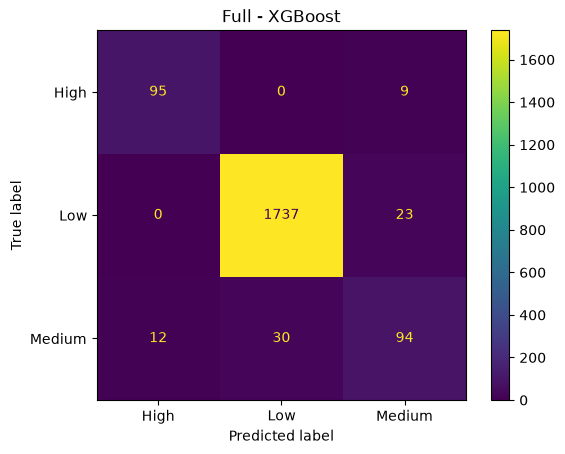

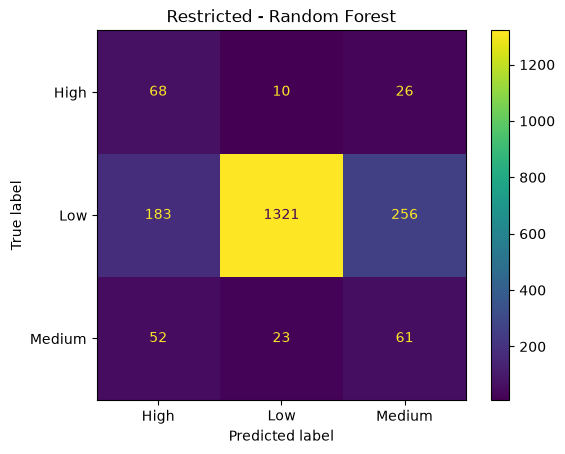

In [74]:
# Confusion Matrices:
for final_name, predictions in final_predictions.items():

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=["High", "Low", "Medium"]
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["High", "Low", "Medium"]
    )

    display.plot()

    plt.title(final_name)

    plt.show()

[Full - XGBoost]:
- Performs well with Macro F1 = 0.8677 & Balanced Accuracy = 0.8639
- Performs well on Low & High Risks
- Medium Risk is the hardest class to predict, meaning the boundaries for Medium/Low and Medium/High are not as distinct (Especially with Medium/Low)

[Restricted - Random Forest]:
- Model performs unevenly across the 3 classes with Macro F1 = 0.4791
- A lot of false High & Medium risk predictions
- The features within the restricted feature set may not be as strong for predicting default risk classes, though we are limited by the synthetic aspect of our dataset.

In [75]:
# Getting the XGBoost Most Important Features
xgb_pipeline = final_pipelines["Full - XGBoost"]
xgb_preprocessor = xgb_pipeline.named_steps["preprocessor"]
xgb_classifier = xgb_pipeline.named_steps["classifier"]

# Getting feature names and importances
xgb_feature_names = (
    xgb_preprocessor
    .get_feature_names_out()
)

xgb_importances = (
    xgb_classifier.feature_importances_
)

# Creating a table and sorting it
xgb_importance_df = pd.DataFrame({
    "Feature": xgb_feature_names,
    "Importance": xgb_importances
})

xgb_importance_df = (
    xgb_importance_df
    .sort_values(
        "Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

xgb_importance_df

,Feature,Importance
0,categorical__Employment_Status_Employed,0.232836
1,numeric__Income_USD,0.162314
2,numeric__Total_BNPL_Debt_USD,0.126218
3,categorical__Late_Payment_History_No,0.126079
4,categorical__Employment_Status_Unemployed,0.113036
5,numeric__Total_BNPL_Active_Loans,0.060314
6,categorical__Employment_Status_Student,0.034908
7,numeric__Credit_Score,0.029728
8,categorical__Shopping_Category_Most_Frequent_F...,0.017134
9,categorical__Shopping_Category_Most_Frequent_T...,0.016797


In [76]:
# Getting the Random Forest Most Important Features
rf_pipeline = final_pipelines["Restricted - Random Forest"]
rf_preprocessor = rf_pipeline.named_steps["preprocessor"]
rf_classifier = rf_pipeline.named_steps["classifier"]

# Getting feature names and importances
rf_feature_names = (
    rf_preprocessor
    .get_feature_names_out()
)

rf_importances = (
    rf_classifier.feature_importances_
)

# Creating a table and sorting it
rf_importance_df = pd.DataFrame({
    "Feature": rf_feature_names,
    "Importance": rf_importances
})

rf_importance_df = (
    rf_importance_df
    .sort_values(
        "Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

rf_importance_df

,Feature,Importance
0,categorical__Employment_Status_Employed,0.289083
1,numeric__Average_Transaction_Value_USD,0.278442
2,numeric__Age,0.219620
3,categorical__Employment_Status_Student,0.087260
4,categorical__Employment_Status_Unemployed,0.077193
5,categorical__Employment_Status_Freelancer,0.032223
6,categorical__Shopping_Category_Most_Frequent_F...,0.004133
7,categorical__Shopping_Category_Most_Frequent_E...,0.004027
8,categorical__Shopping_Category_Most_Frequent_H...,0.003494
9,categorical__Shopping_Category_Most_Frequent_T...,0.002277


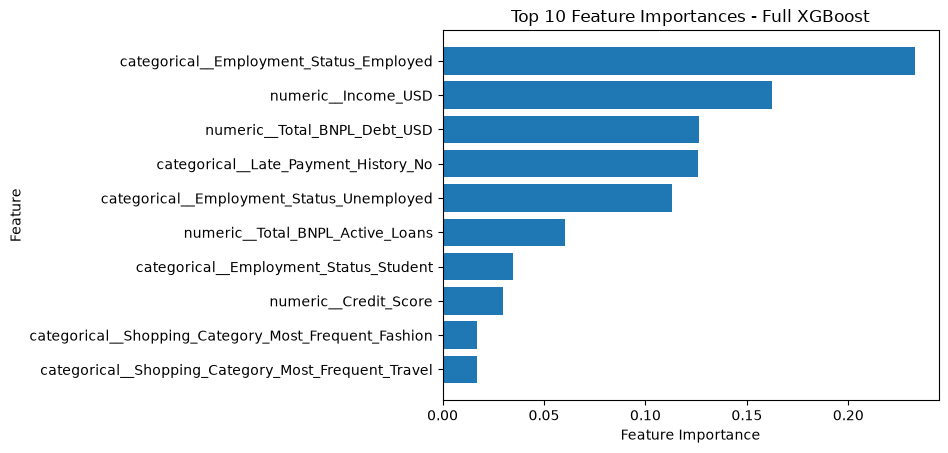

In [77]:
top_xgb = xgb_importance_df.head(10)

plt.figure()

plt.barh(
    top_xgb["Feature"],
    top_xgb["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.title(
    "Top 10 Feature Importances - Full XGBoost"
)

plt.gca().invert_yaxis()

plt.show()

- Employment_Status_Employed seems to be extremely important, though it's only a 1/4th of the representation of Employment Status, so we can't say that being employed is necessarily the most important compared to the 2nd most important feature (Income_USD)
- The Full model relies heavily on the 4 variables we've been concerned about.
- We see Income_USD, Total_BNPL_Debt_USD, Total_BNPL_Active_Loans, and Credit_Score in our top 10
- We proably were just able to reproduce the dataset's synthetic risk classifications with this full model

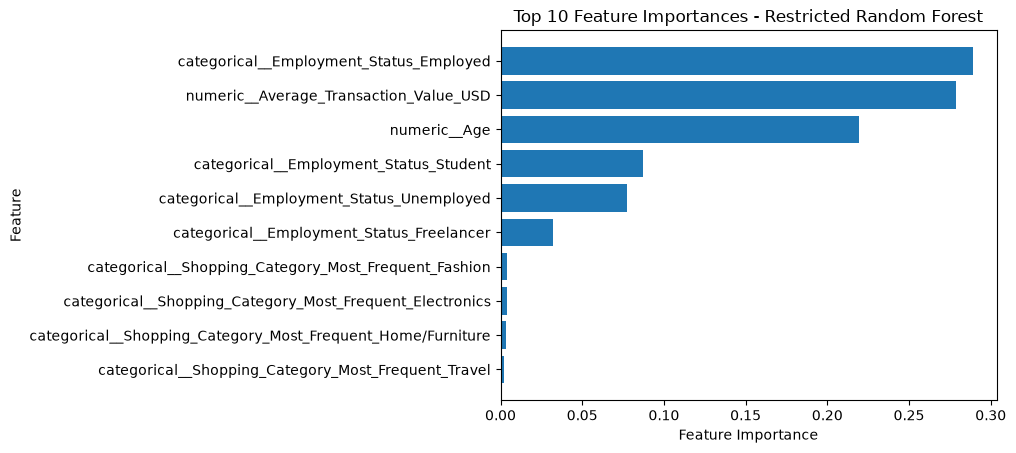

In [78]:
top_rf = rf_importance_df.head(10)

plt.figure()

plt.barh(
    top_rf["Feature"],
    top_rf["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.title(
    "Top 10 Feature Importances - Restricted Random Forest"
)

plt.gca().invert_yaxis()

plt.show()

- This model lost access to information that we were worried about from the full feature set.
- We see employment is an important feature, but once again since it's only a 1/4th of the total feature (Employment Status) it wouldn't be fair to compare it against something like Average_Transaction_Value_USD or Age since it's not necessarily an independent predictor.
- What we learn from this is that the remaining characteristics contain less discriminating information about the synthetic target.